# Training on Google Colab
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diego-dupuy/Paediatric-pneumonia-classifier/blob/main/notebooks/train_colab.ipynb)

This notebook only **runs** the code in `src/` on a GPU: it downloads the dataset, trains the three
experiments, evaluates them and generates the Grad-CAM figures. All the logic lives in the `.py` files.

**Before running:**
1. *Runtime → Change runtime type → T4 GPU*.
2. Kaggle key: create a token in kaggle.com → *Settings → API*, then in Colab click the 🔑 icon (left bar),
   add a secret called `KAGGLE_API_TOKEN` with the token as value and enable *Notebook access*.

Results are copied to Google Drive after each experiment. If the session disconnects, run everything
again: finished experiments are restored from Drive and skipped.

In [1]:
# 1) Get the code: clone the repository and move into it
import os
if not os.path.exists("Paediatric-pneumonia-classifier"):
    !git clone -q https://github.com/diego-dupuy/Paediatric-pneumonia-classifier
os.chdir("Paediatric-pneumonia-classifier")

# The only library not pre-installed in Colab
!pip install -q grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# 2) Download the dataset from Kaggle.
# The key is read from Colab secrets, so it never appears in the code.
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
!kaggle datasets download -q -d paultimothymooney/chest-xray-pneumonia
!unzip -q -n chest-xray-pneumonia.zip -d data   # -n: do not overwrite if already extracted
!ls data/chest_xray                              # expected: test  train  val

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
chest_xray  __MACOSX  test  train  val


In [3]:
# 3) Google Drive: keep results safe if the Colab session disconnects
from google.colab import drive
drive.mount("/content/drive")
DRIVE_RESULTS = "/content/drive/MyDrive/neumonia_results"

# Restore experiments finished in a previous session (if any)
if os.path.exists(DRIVE_RESULTS):
    !mkdir -p results && cp -r "{DRIVE_RESULTS}/." results/
    print("restored:", sorted(os.listdir("results")))

Mounted at /content/drive


## What the data augmentation does
Each training epoch sees a slightly different version of every X-ray (random crop/zoom, small rotation,
brightness and contrast), so the network cannot rely on borders or corners always being in the same place.
Below: one training image and 5 random augmented versions.

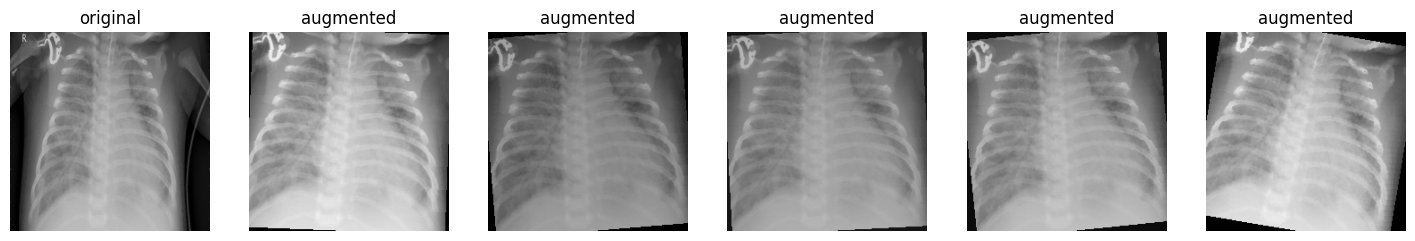

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from src.dataset import train_transform

path = sorted(os.listdir("data/chest_xray/train/PNEUMONIA"))[0]
image = Image.open(f"data/chest_xray/train/PNEUMONIA/{path}").convert("RGB")

# First 3 steps of the training transform (crop, rotation, brightness/contrast),
# without tensor conversion and normalisation so the result can be displayed
augment = transforms.Compose(train_transform(True).transforms[:3])

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(image.resize((224, 224)), cmap="gray"); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(image)); ax.set_title("augmented")   # a new random version each time
for ax in axes: ax.axis("off")
plt.show()

## Experiments
Each experiment adds **one** change to the previous one, so the effect of each change can be measured.

| Name | What changes |
|---|---|
| `baseline` | no class weights, no augmentation (reference) |
| `weighted` | + class weights in the loss, to compensate the imbalance (≈3 pneumonia per normal X-ray) |
| `weighted_aug` | + data augmentation |

Each one takes ~10-15 min on a T4. Training stops early if the validation loss does not improve for 4 epochs.

In [5]:
def run_experiment(name):
    """Train + evaluate one experiment, then copy its results to Drive.
    Skipped if it was already finished (results restored from Drive)."""
    if os.path.exists(f"results/{name}/metrics.json"):
        print(f"{name}: already finished, skipping")
        return
    !python -m src.train --experiment {name}       # trains and saves results/<name>/model.pth
    !python -m src.evaluate --experiment {name}    # metrics, confusion matrix, training curves
    !mkdir -p "{DRIVE_RESULTS}" && cp -r "results/{name}" "{DRIVE_RESULTS}/"

In [6]:
run_experiment("baseline")

device: cuda | experiment: baseline
train: 4437 images [1152, 3285] | val: 779 | test: 624  (counts = [Normal, Pneumonia])
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 175MB/s]
epoch  1 [80s]  train loss 0.2323 acc 0.906 | val loss 0.1414 acc 0.946
epoch  2 [78s]  train loss 0.1683 acc 0.936 | val loss 0.1235 acc 0.946
epoch  3 [80s]  train loss 0.1466 acc 0.944 | val loss 0.1275 acc 0.963
epoch  4 [78s]  train loss 0.1325 acc 0.949 | val loss 0.1026 acc 0.959
epoch  5 [78s]  train loss 0.1246 acc 0.954 | val loss 0.1067 acc 0.969
epoch  6 [78s]  train loss 0.1260 acc 0.948 | val loss 0.0949 acc 0.965
epoch  7 [78s]  train loss 0.1094 acc 0.958 | val loss 0.1041 acc 0.970
epoch  8 [79s]  train loss 0.1221 acc 0.954 | val loss 0.0882 acc 0.967
epoch  9 [78s]  train loss 0.1085 acc 0.960 | val loss 0.0892 acc 0.970
epoch 10 [79s]  train loss 0.1033 acc 0.963 | val loss 0

In [7]:
run_experiment("weighted")

device: cuda | experiment: weighted
train: 4437 images [1152, 3285] | val: 779 | test: 624  (counts = [Normal, Pneumonia])
class weights [Normal, Pneumonia]: [1.92578125, 0.6753424406051636]
epoch  1 [79s]  train loss 0.2777 acc 0.888 | val loss 0.1677 acc 0.947
epoch  2 [80s]  train loss 0.1925 acc 0.923 | val loss 0.1274 acc 0.959
epoch  3 [80s]  train loss 0.1675 acc 0.938 | val loss 0.1864 acc 0.933
epoch  4 [78s]  train loss 0.1514 acc 0.945 | val loss 0.1200 acc 0.964
epoch  5 [79s]  train loss 0.1437 acc 0.946 | val loss 0.1374 acc 0.955
epoch  6 [79s]  train loss 0.1424 acc 0.948 | val loss 0.1182 acc 0.964
epoch  7 [80s]  train loss 0.1250 acc 0.956 | val loss 0.1382 acc 0.955
epoch  8 [78s]  train loss 0.1395 acc 0.947 | val loss 0.1012 acc 0.968
epoch  9 [78s]  train loss 0.1233 acc 0.953 | val loss 0.1212 acc 0.961
epoch 10 [79s]  train loss 0.1184 acc 0.955 | val loss 0.0878 acc 0.970
epoch 11 [79s]  train loss 0.1267 acc 0.953 | val loss 0.1377 acc 0.950
epoch 12 [77s]  t

In [8]:
run_experiment("weighted_aug")

device: cuda | experiment: weighted_aug
train: 4437 images [1152, 3285] | val: 779 | test: 624  (counts = [Normal, Pneumonia])
class weights [Normal, Pneumonia]: [1.92578125, 0.6753424406051636]
epoch  1 [88s]  train loss 0.3643 acc 0.845 | val loss 0.3627 acc 0.833
epoch  2 [89s]  train loss 0.2566 acc 0.900 | val loss 0.2512 acc 0.911
epoch  3 [89s]  train loss 0.2303 acc 0.914 | val loss 0.5540 acc 0.739
epoch  4 [88s]  train loss 0.2177 acc 0.915 | val loss 0.2381 acc 0.913
epoch  5 [89s]  train loss 0.2072 acc 0.917 | val loss 0.3334 acc 0.850
epoch  6 [89s]  train loss 0.2019 acc 0.919 | val loss 0.3194 acc 0.865
epoch  7 [88s]  train loss 0.1950 acc 0.922 | val loss 0.3862 acc 0.836
epoch  8 [89s]  train loss 0.1941 acc 0.920 | val loss 0.1941 acc 0.931
epoch  9 [90s]  train loss 0.1849 acc 0.926 | val loss 0.2361 acc 0.905
epoch 10 [90s]  train loss 0.1897 acc 0.925 | val loss 0.2139 acc 0.918
epoch 11 [89s]  train loss 0.1893 acc 0.924 | val loss 0.2611 acc 0.891
epoch 12 [86s

## Comparison
Columns without prefix are measured on the **test set** (624 X-rays). Columns starting with `val_` are
measured on the **validation set**: the final model is chosen with these, and the test set is only reported.

In [9]:
!python -m src.evaluate --compare

              sensitivity  specificity  precision  accuracy     f1    auc     TP     TN     FP    FN  val_sensitivity  val_specificity  val_auc
baseline            0.985        0.530      0.777     0.814  0.869  0.936  384.0  124.0  110.0   6.0            0.981            0.921    0.995
weighted            0.982        0.521      0.774     0.809  0.866  0.939  383.0  122.0  112.0   7.0            0.978            0.921    0.995
weighted_aug        0.959        0.769      0.874     0.888  0.914  0.953  374.0  180.0   54.0  16.0            0.956            0.958    0.989


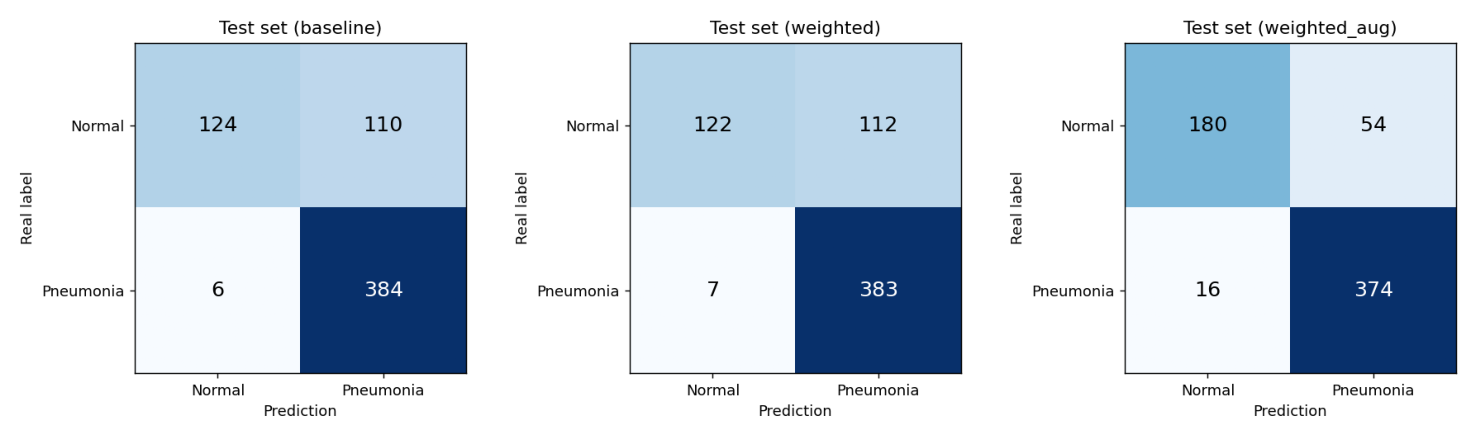

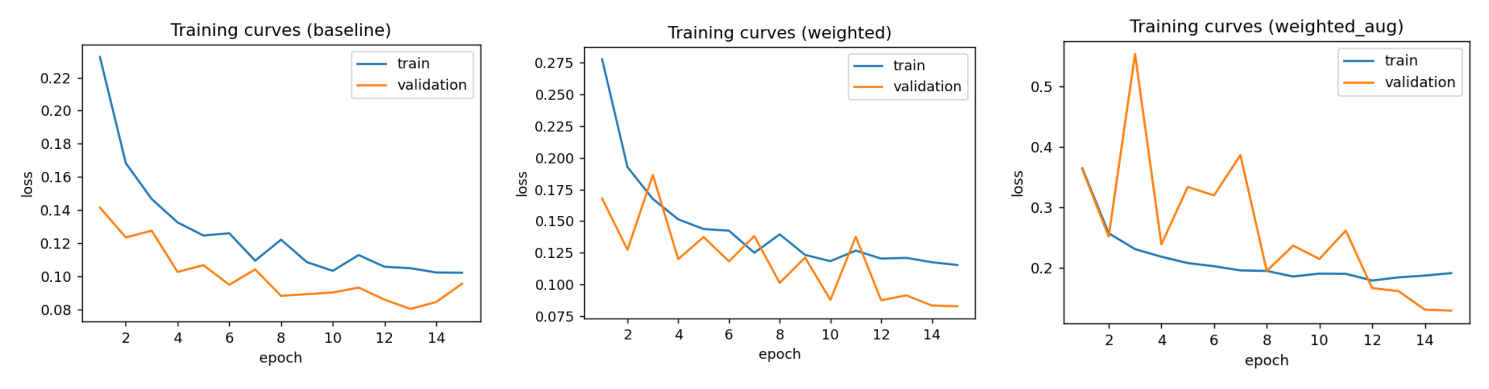

In [10]:
# Confusion matrices (top) and training curves (bottom) of the three experiments
names = ["baseline", "weighted", "weighted_aug"]
for figure in ["confusion_matrix", "training_curves"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, name in zip(axes, names):
        ax.imshow(plt.imread(f"results/{name}/{figure}.png")); ax.axis("off")
    plt.tight_layout(); plt.show()

## Grad-CAM: where does the model look?
`central_attention` = share of the heat map inside the central part of the image (15 % margin removed on
each side). If attention were spread evenly it would be ≈ 0.49; higher = more focused on the centre (lungs),
lower = more on borders and corners. Compared for the reference model and the model with augmentation.

In [11]:
for name in ["baseline", "weighted_aug"]:
    !python -m src.gradcam --experiment {name}
    !cp -r "results/{name}" "{DRIVE_RESULTS}/"     # save the Grad-CAM outputs too

train: 4437 images [1152, 3285] | val: 779 | test: 624  (counts = [Normal, Pneumonia])
{
  "false_negatives": 6,
  "central_attention_all_pneumonia": 0.5068652569101407,
  "central_attention_false_negatives": 0.3517720053593318
}
train: 4437 images [1152, 3285] | val: 779 | test: 624  (counts = [Normal, Pneumonia])
{
  "false_negatives": 16,
  "central_attention_all_pneumonia": 0.5606798196450258,
  "central_attention_false_negatives": 0.4554696511477232
}


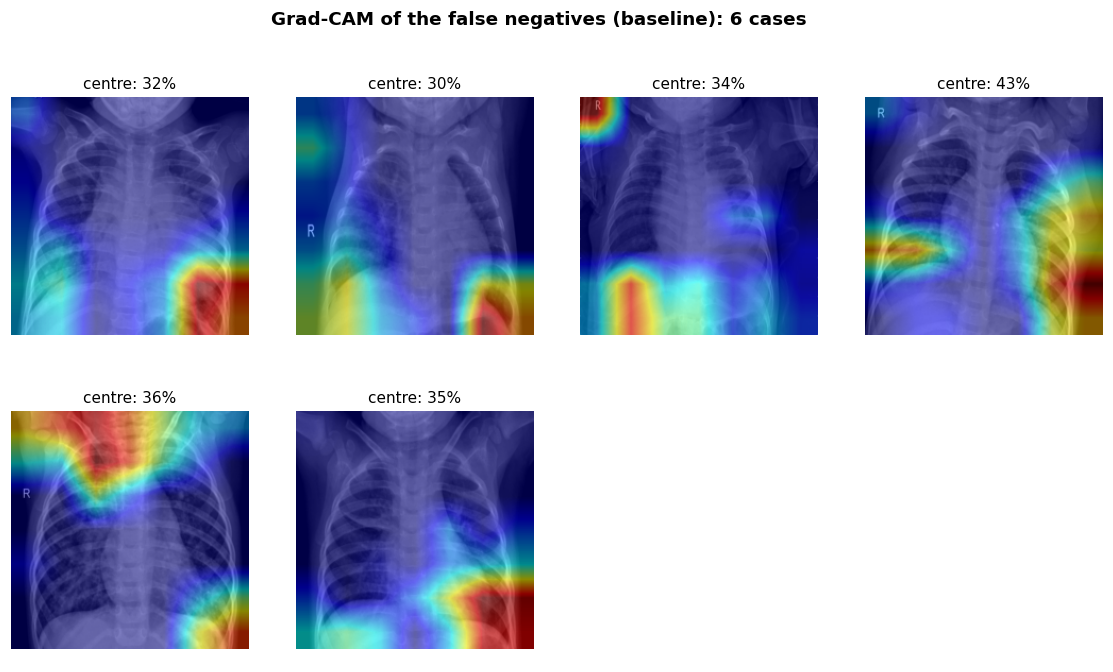

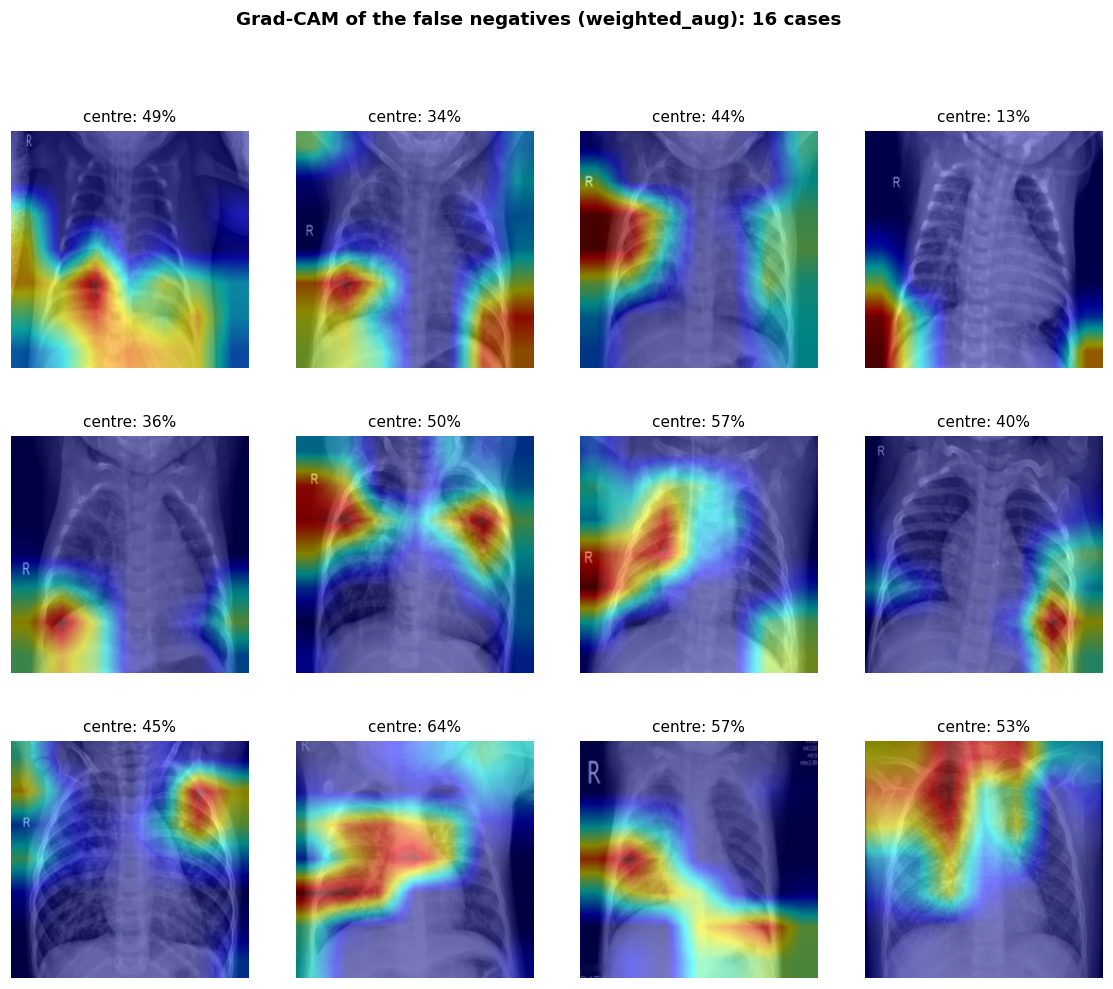

In [12]:
# Grid of false negatives (pneumonia X-rays predicted as normal) with their heat maps
from IPython.display import Image as Show, display
for name in ["baseline", "weighted_aug"]:
    path = f"results/{name}/gradcam_false_negatives.png"
    if os.path.exists(path):
        display(Show(path))